Load and Preprocess Data

In [89]:
#Imports and Setup
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import *
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Lambda, GlobalAveragePooling2D, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam , Adamax
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import backend as K
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import class_weight

In [90]:
# Set the path to dataset
test_dir = "C:/Users/MARBLE/Desktop/Python projects/chest_xray_tensorflow/data/chest_xray/big_test"
base_dir = "C:/Users/MARBLE/Desktop/Python projects/chest_xray_tensorflow/data/chest_xray/big_train"

# Set image size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

In [91]:
# Load train and val with split
train_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.3,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 5396 files belonging to 4 classes.
Using 3778 files for training.
Found 5396 files belonging to 4 classes.
Using 1618 files for validation.
Found 968 files belonging to 4 classes.


In [92]:
# data_augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
])

In [93]:
# Get the actual class labels
y_train = []
for _, labels in train_ds.unbatch():
    y_train.append(np.argmax(labels.numpy()))
class_weights = {
    0: 1.0,    # Bacterial
    1: 1.5,    # Normal — boost recall
    2: 0.8,    # Pneumothorax — already great
    3: 1.7     # Viral — often confused
}
class_weights_dict = dict(enumerate(class_weights))

In [94]:
# Prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE

# Preprocessing with optional augmentation
def preprocess(ds, augment=False):
    if augment:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Apply augmentation only to training data
train_ds = preprocess(train_ds, augment=True)
val_ds = preprocess(val_ds)
test_ds = preprocess(test_ds)

**MobileNetV2 Model**

In [95]:
# Build the Model with MobileNetV2
# Load and partially unfreeze MobileNetV2
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = True  # Freeze feature extractor

# Freeze the first N layers
fine_tune_at = 40  # fine-tune from layer 100 onwards
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Model definition
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax', kernel_regularizer=regularizers.l2(0.001))
])

"""import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import BatchNormalization, Dropout, Dense

# 1. Load the MobileNetV2 model (without the top layer for fine-tuning)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the model weights
for layer in base_model.layers:
    layer.trainable = False

# 2. Define the Keras input
input_layer = keras.Input(shape=(224, 224, 3), dtype=tf.float32)

# 3. Apply MobileNetV2 model
x = base_model(input_layer)

# 4. Add Global Average Pooling Layer
x = keras.layers.GlobalAveragePooling2D()(x)

# 5. Add Batch Normalization Layer
x = BatchNormalization()(x)

# 6. Add Dropout Layer 1
x = Dropout(0.45)(x)

# 7. Add Dense Layer 1
x = Dense(220, activation='relu')(x)

# 8. Add Dropout Layer 2
x = Dropout(0.25)(x)

# 9. Add Dense Layer 2
x = Dense(60, activation='relu')(x)

# 10. Add the Output Layer (Sigmoid for binary classification)
output_layer = Dense(4, activation='sigmoid')(x)

# 11. Define the full Keras Model using the functional API
model = keras.Model(inputs=input_layer, outputs=output_layer)

"""

"import tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras.applications import MobileNetV2\nfrom tensorflow.keras.layers import BatchNormalization, Dropout, Dense\n\n# 1. Load the MobileNetV2 model (without the top layer for fine-tuning)\nbase_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))\n\n# Freeze the model weights\nfor layer in base_model.layers:\n    layer.trainable = False\n\n# 2. Define the Keras input\ninput_layer = keras.Input(shape=(224, 224, 3), dtype=tf.float32)\n\n# 3. Apply MobileNetV2 model\nx = base_model(input_layer)\n\n# 4. Add Global Average Pooling Layer\nx = keras.layers.GlobalAveragePooling2D()(x)\n\n# 5. Add Batch Normalization Layer\nx = BatchNormalization()(x)\n\n# 6. Add Dropout Layer 1\nx = Dropout(0.45)(x)\n\n# 7. Add Dense Layer 1\nx = Dense(220, activation='relu')(x)\n\n# 8. Add Dropout Layer 2\nx = Dropout(0.25)(x)\n\n# 9. Add Dense Layer 2\nx = Dense(60, activation='relu')(x)\n\n# 10. Add the Out

In [96]:
# Compile Model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=CategoricalCrossentropy(label_smoothing=0.01),
    metrics=['accuracy']
)

# Summary
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 2,194,948 (8.37 MB)

 Non-trainable params: 68,160 (266.25 KB)

In [97]:
lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts(
    initial_learning_rate=1e-4,
    first_decay_steps=1000,
    t_mul=2.0,
    m_mul=0.9,
    alpha=1e-6
)
optimizer = Adam(learning_rate=lr_schedule)

In [98]:
# Add call backs
callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
    ModelCheckpoint('best_model.keras', save_best_only=True)
]


In [99]:
# Train the Model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
    class_weight=class_weights_dict
)



Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 1051s 3s/step - accuracy: 0.5495 - loss: 0.9337 - val_accuracy: 0.4951 - val_loss: 2.8338 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 389s 3s/step - accuracy: 0.7004 - loss: 0.3405 - val_accuracy: 0.5253 - val_loss: 2.2604 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 379s 3s/step - accuracy: 0.7181 - loss: 0.2893 - val_accuracy: 0.4333 - val_loss: 3.5463 - learning_rate: 1.0000e-04
Epoch 4/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 386s 3s/step - accuracy: 0.7088 - loss: 0.2589 - val_accuracy: 0.4635 - val_loss: 3.1529 - learning_rate: 1.0000e-04
Epoch 5/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 367s 3s/step - accuracy: 0.7212 - loss: 0.2484 - val_accuracy: 0.4166 - val_loss: 3.8867 - learning_rate: 3.0000e-05
Epoch 6/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 369s 3s/step - accuracy: 0.7251 - loss: 0.2284 - val_accuracy: 0.4116 - val_loss: 3.5576 - learning_rate: 3.0000e-05
Epoch 7/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 351s 3s/step - ac

In [100]:
test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.2%}')


31/31 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.6278 - loss: 1.8244 
Test accuracy: 62.40%


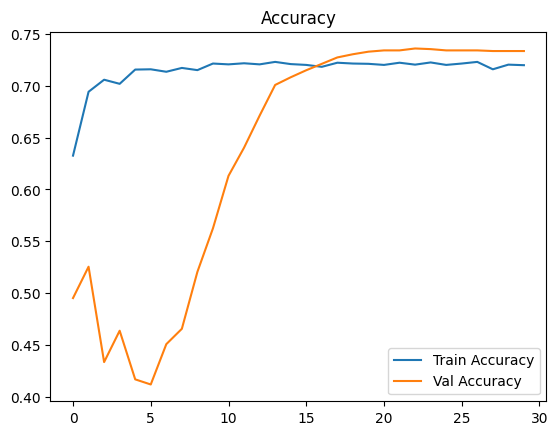

In [101]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')
plt.show()

In [102]:
import itertools

y_true = []
y_pred = []
for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels, axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))



1/1 ━━━━━━━━━━━━━━━━━━━━ 29s 29s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 906ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 983ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 859ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 947ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 905ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 884ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 916ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 907ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 877ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 864ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 975ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 880ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 947ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 948ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 884ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 937ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 935ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 937ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 924ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 959ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 919ms/s

c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to c

In [103]:
model.save("new3_model_with_class_weight.h5")
 

In [104]:
pip install gradio tensorflow

Note: you may need to restart the kernel to use updated packages.


In [106]:
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# Load the trained model
model = tf.keras.models.load_model("new3_model_with_class_weight.h5")

# Define class names
class_names = ["VIRAL_PNEUMONIA", "BACTERIAL_PNEUMONIA", "PNEUMOTHORAX", "NORMAL"]

# Preprocess the uploaded image
def preprocess_image(img: Image.Image) -> np.ndarray:
    img = img.resize((224, 224))
    img = np.array(img) / 255.0
    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    elif img.shape[-1] != 3:
        img = img[..., :3]
    return img.reshape(1, 224, 224, 3)

# Predict function
def predict_xray(image):
    img = preprocess_image(image)
    preds = model.predict(img)[0]
    results = {class_names[i]: float(preds[i]) for i in range(len(class_names))}
    return results

# Gradio UI setup
title = "🩻 Chest X-Ray Pneumonia Classifier (4-Class)"
description = "Upload a chest X-ray image to check for signs of VIRAL_PNEUMONIA, BACTERIAL_PNEUMONIA, PNEUMOTHORAX, or NORMAL. This model is powered by MobileNetV2."

gr.Interface(
    fn=predict_xray,
    inputs=gr.Image(type="pil", label="Upload Chest X-Ray"),
    outputs=gr.Label(num_top_classes=4, label="Prediction"),
    title=title,
    description=description,
    theme="default",
    allow_flagging="never"
).launch()


c:\Users\MARBLE\Desktop\Python projects\school_management_system\venv\Lib\site-packages\gradio\interface.py:416: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated.Use `flagging_mode` instead.
  warnings.warn(


* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.
